# Practical No. 8 — Implement Autoencoders to Compress and Reconstruct MNIST Images

**Aim:** To implement an Autoencoder Neural Network for compressing and reconstructing handwritten digit images from the MNIST dataset.

## Objectives
- Understand Autoencoders and representation learning.
- Compress high-dimensional image data into a lower-dimensional latent representation.
- Reconstruct original images from compressed features.
- Evaluate reconstruction quality.
- Visualize original and reconstructed MNIST images.



## Theory

**What is an Autoencoder?** An Autoencoder is an unsupervised neural network that learns to encode input data into a compressed representation and then reconstruct the original data from that representation.

- **Encoder:** Compresses the input into a lower-dimensional representation.
- **Decoder:** Reconstructs the original input from the compressed representation.

**Working principle:** Input Image → Encoder → Latent Space → Decoder → Reconstructed Image.

**Why use Autoencoders?** Data compression, feature extraction, image denoising, dimensionality reduction, anomaly detection, and image reconstruction.

**MNIST dataset:** 60,000 training images, 10,000 test images, grayscale 28 × 28 pixels, digits 0–9.

**Mathematical representation:** Encoder: `z = f(x)`; Decoder: `x̂ = g(z)`, where `x` is the input image, `z` is the latent representation, and `x̂` is the reconstructed image.

## Software Requirements
- Python 3.x
- TensorFlow / Keras
- NumPy
- Matplotlib

This notebook runs in Google Colab or a Jupyter environment with the libraries installed. MNIST is loaded through TensorFlow/Keras.

## Algorithm
1. Import required libraries.
2. Load MNIST dataset.
3. Normalize image pixel values.
4. Flatten images into vectors.
5. Build encoder network.
6. Build decoder network.
7. Train autoencoder.
8. Compress test images.
9. Reconstruct images.
10. Compare original and reconstructed images.

## Program — Step 1: Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

## Step 2: Load MNIST Dataset

In [2]:
(X_train, _), (X_test, _) = mnist.load_data()
print("Training Images:", X_train.shape)
print("Testing Images:", X_test.shape)

Training Images: (60000, 28, 28)
Testing Images: (10000, 28, 28)


## Step 3: Normalize Data

In [3]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

## Step 4: Flatten Images

In [4]:
X_train = X_train.reshape((len(X_train), 784))
X_test = X_test.reshape((len(X_test), 784))
print("Flattened Training Shape:", X_train.shape)
print("Flattened Testing Shape:", X_test.shape)

Flattened Training Shape: (60000, 784)
Flattened Testing Shape: (10000, 784)


## Step 5: Define Autoencoder Architecture

The source practical uses **784 input features → 128 units → 32 encoded features → 128 units → 784 reconstructed features**.

In [5]:
input_dim = 784
encoding_dim = 32

input_img = Input(shape=(input_dim,))

# Encoder
encoded = Dense(128, activation='relu')(input_img)
encoded = Dense(encoding_dim, activation='relu')(encoded)

# Decoder
decoded = Dense(128, activation='relu')(encoded)
decoded = Dense(input_dim, activation='sigmoid')(decoded)

autoencoder = Model(input_img, decoded)

## Step 6: Compile Model

In [6]:
autoencoder.compile(optimizer='adam', loss='binary_crossentropy')
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

## Step 7: Train Autoencoder

Train for **20 epochs**, batch size **256**, and validate reconstruction on MNIST test images as specified in the document. *(Corrected `shufle` to `shuffle` for runnable Python.)*

In [8]:
import numpy as np
import tensorflow as tf

# Keep data in float32 format
X_train = np.asarray(X_train, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

# Use TensorFlow dataset with small batches
batch_size = 32

train_dataset = tf.data.Dataset.from_generator(
    lambda: ((batch, batch) for batch in np.array_split(X_train, 1875)),
    output_signature=(
        tf.TensorSpec(shape=(None, 784), dtype=tf.float32),
        tf.TensorSpec(shape=(None, 784), dtype=tf.float32)
    )
)

val_dataset = tf.data.Dataset.from_generator(
    lambda: ((batch, batch) for batch in np.array_split(X_test, 313)),
    output_signature=(
        tf.TensorSpec(shape=(None, 784), dtype=tf.float32),
        tf.TensorSpec(shape=(None, 784), dtype=tf.float32)
    )
)

history = autoencoder.fit(
    train_dataset,
    epochs=20,
    validation_data=val_dataset
)

Epoch 1/20


c:\Users\shree\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - loss: 0.1449 - val_loss: 0.1118
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - loss: 0.1015 - val_loss: 0.1017
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0945 - val_loss: 0.0956
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0909 - val_loss: 0.0926
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0887 - val_loss: 0.0905
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0873 - val_loss: 0.0889
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0863 - val_loss: 0.0876
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0856 - val_loss: 0.0869
Epoch 9/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0850 - val_loss: 0.0863
Epoch 10/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0846 - val_loss: 0.0861
Epoch 11/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0842 - val_loss: 0.0858
Epoch 12/20
1875/1875 ━━━━━━━━━━━━━━━━━

## Step 8: Reconstruct Images

In [9]:
decoded_images = autoencoder.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


## Step 9: Display Original and Reconstructed Images

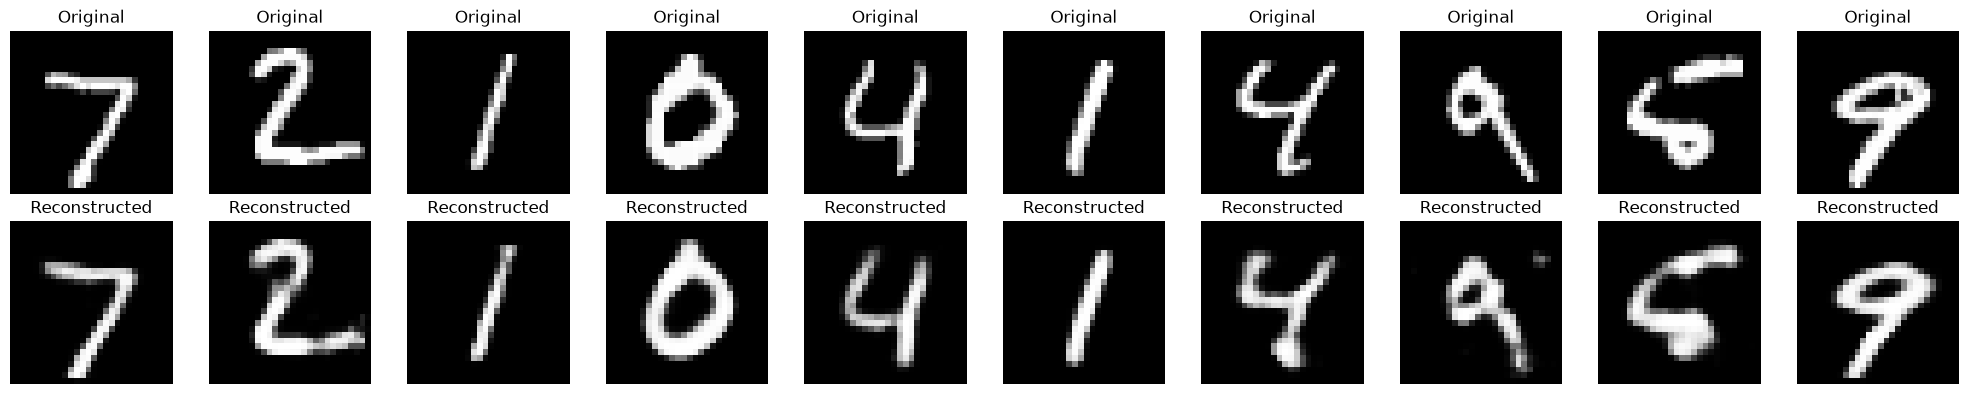

In [10]:
n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Original images
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title('Original')
    plt.axis('off')

    # Reconstructed images
    ax = plt.subplot(2, n, i + n + 1)
    plt.imshow(decoded_images[i].reshape(28, 28), cmap='gray')
    plt.title('Reconstructed')
    plt.axis('off')
plt.tight_layout()
plt.show()

## Creating Separate Encoder Model

This section extracts the compressed **32-feature** representation from the trained encoder.

In [11]:
encoder = Model(input_img, encoded)
compressed_data = encoder.predict(X_test)
print('Compressed Shape:', compressed_data.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 900us/step
Compressed Shape: (10000, 32)


## Result

An Autoencoder was implemented on the MNIST dataset to learn a compressed representation of handwritten digit images and reconstruct them. The architecture reduces **784 features to 32 features** while aiming to preserve essential image characteristics. Review the cell outputs above to assess the reconstruction quality for your run.